<a href="https://colab.research.google.com/github/vibzium/Uber/blob/main/Uber.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Data Preprocessing

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
from statsmodels.tsa.seasonal import seasonal_decompose
from matplotlib.dates import DateFormatter
from statsmodels.tsa.arima.model import ARIMA
from prophet import Prophet

In [ ]:
df = pd.read_csv('/content/Uber-Jan-Feb-FOIL.csv')

In [ ]:
df

,dispatching_base_number,date,active_vehicles,trips
0,B02512,1/1/2015,190,1132
1,B02765,1/1/2015,225,1765
2,B02764,1/1/2015,3427,29421
3,B02682,1/1/2015,945,7679
4,B02617,1/1/2015,1228,9537
...,...,...,...,...
349,B02764,2/28/2015,3952,39812
350,B02617,2/28/2015,1372,14022
351,B02682,2/28/2015,1386,14472
352,B02512,2/28/2015,230,1803


In [ ]:
# Display basic information
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 354 entries, 0 to 353
Data columns (total 4 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   dispatching_base_number  354 non-null    object
 1   date                     354 non-null    object
 2   active_vehicles          354 non-null    int64 
 3   trips                    354 non-null    int64 
dtypes: int64(2), object(2)
memory usage: 11.2+ KB


,active_vehicles,trips
count,354.000000,354.000000
mean,1307.435028,11667.316384
std,1162.510626,10648.284865
min,112.000000,629.000000
25%,296.750000,2408.500000
50%,1077.000000,9601.000000
75%,1417.000000,13711.250000
max,4395.000000,45858.000000


In [ ]:
# Unique bases
print("\nUnique Uber Bases:")
print(df['dispatching_base_number'].unique())


Unique Uber Bases:
['B02512' 'B02765' 'B02764' 'B02682' 'B02617' 'B02598']


In [ ]:
# Convert date to datetime and extract features
df['date'] = pd.to_datetime(df['date'])
df['month'] = df['date'].dt.month
df['day'] = df['date'].dt.day
df['day_of_week'] = df['date'].dt.dayofweek  # Monday=0, Sunday=6
df['weekend'] = df['day_of_week'].isin([5, 6])  # 5=Saturday, 6=Sunday

# Verify the first 5 rows
print("DataFrame with new datetime features:")
df.head()

DataFrame with new datetime features:


,dispatching_base_number,date,active_vehicles,trips,month,day,day_of_week,weekend
0,B02512,2015-01-01,190,1132,1,1,3,False
1,B02765,2015-01-01,225,1765,1,1,3,False
2,B02764,2015-01-01,3427,29421,1,1,3,False
3,B02682,2015-01-01,945,7679,1,1,3,False
4,B02617,2015-01-01,1228,9537,1,1,3,False


Exploratory Data Analysis (EDA)

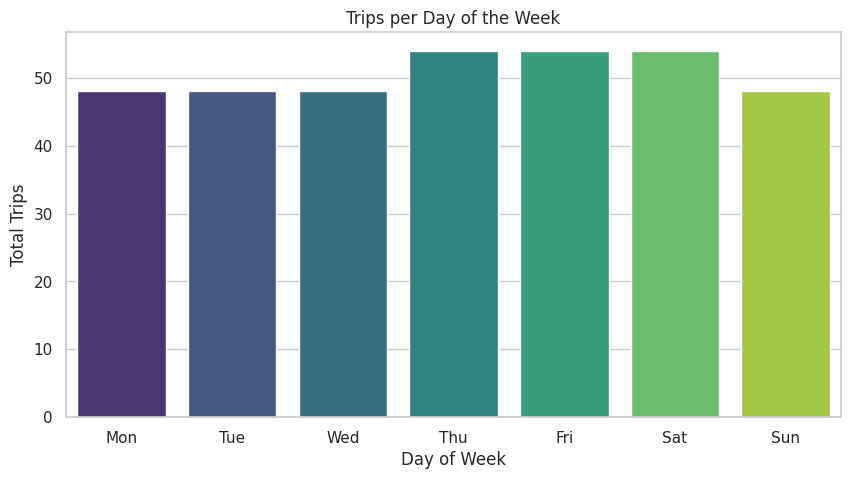

In [ ]:
# Trips per day of the week
plt.figure(figsize=(10, 5))
weekday_names = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
sns.countplot(data=df, x='day_of_week', palette='viridis')
plt.title("Trips per Day of the Week")
plt.xticks(range(7), weekday_names)
plt.xlabel("Day of Week")
plt.ylabel("Total Trips")
plt.show()

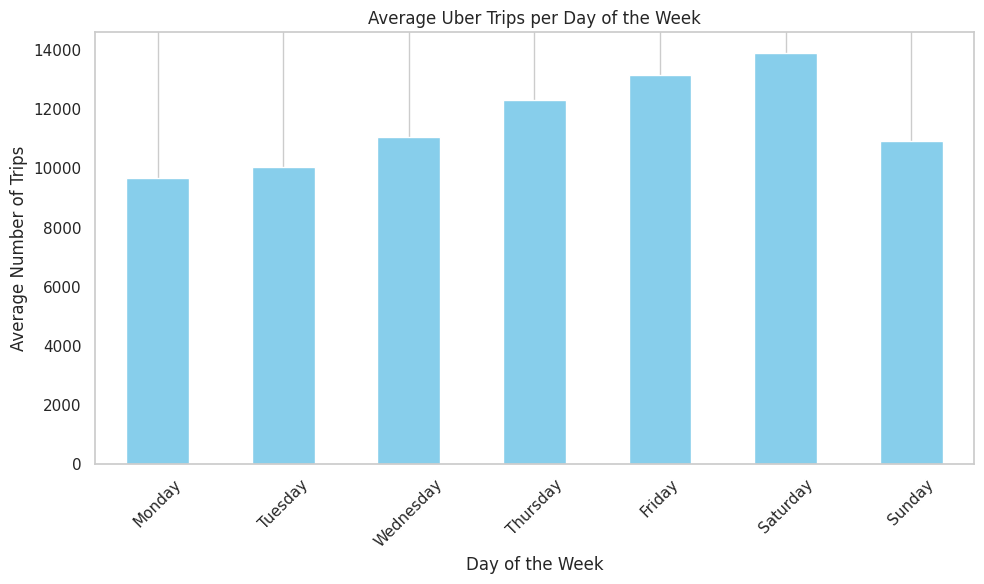

In [ ]:
# Visualize the average trips per day of the week
plt.figure(figsize=(10, 6))
avg_trips_by_day.plot(kind='bar', color='skyblue')
plt.title('Average Uber Trips per Day of the Week')
plt.xlabel('Day of the Week')
plt.ylabel('Average Number of Trips')
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.tight_layout()
plt.show()

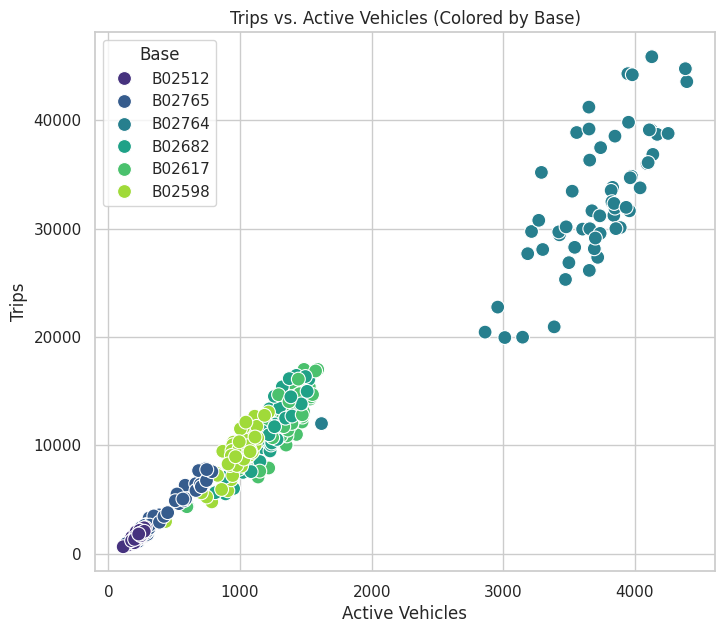

In [ ]:
# Correlation: Active Vehicles vs. Trips
plt.figure(figsize=(8, 7))
sns.scatterplot(
    data=df,
    x='active_vehicles',
    y='trips',
    hue='dispatching_base_number',
    palette='viridis',
    s=100
)
plt.title('Trips vs. Active Vehicles (Colored by Base)')
plt.xlabel('Active Vehicles')
plt.ylabel('Trips')
plt.legend(title='Base')
plt.grid(True)
plt.show()

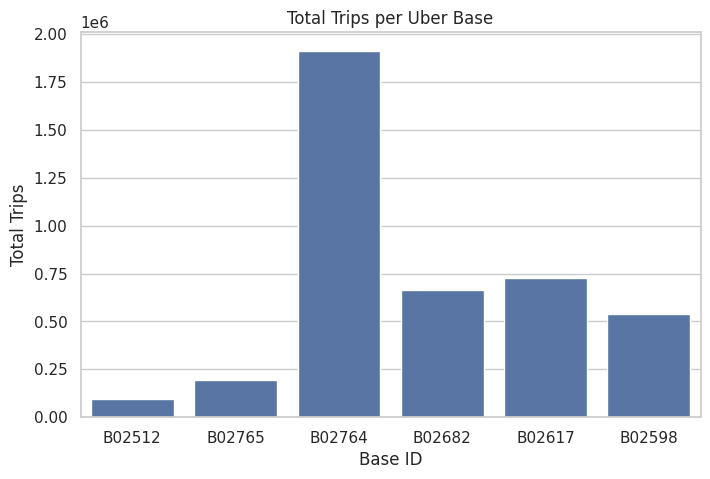

In [ ]:
# Set style
sns.set(style="whitegrid")

# Trips per base (categorical)
plt.figure(figsize=(8, 5))
sns.barplot(data=df, x='dispatching_base_number', y='trips', estimator=sum, ci=None)
plt.title("Total Trips per Uber Base")
plt.xlabel("Base ID")
plt.ylabel("Total Trips")
plt.show()

Feature Engineering

In [ ]:
# Define features (X) and target (y)
X = df.drop(['trips'], axis=1)  # Features
y = df['trips']  # Target variable

print("\nFeatures (X) Shape:", X.shape)
print("Target (y) Shape:", y.shape)


Features (X) Shape: (354, 11)
Target (y) Shape: (354,)


In [ ]:
# Split data into train & test sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialize and train Random Forest
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# Predict on test data
y_pred = rf_model.predict(X_test)

print("\nModel Training Complete!")


Model Training Complete!



Model Performance:
- Mean Squared Error (MSE): 1513379.90
- R² Score: 0.99


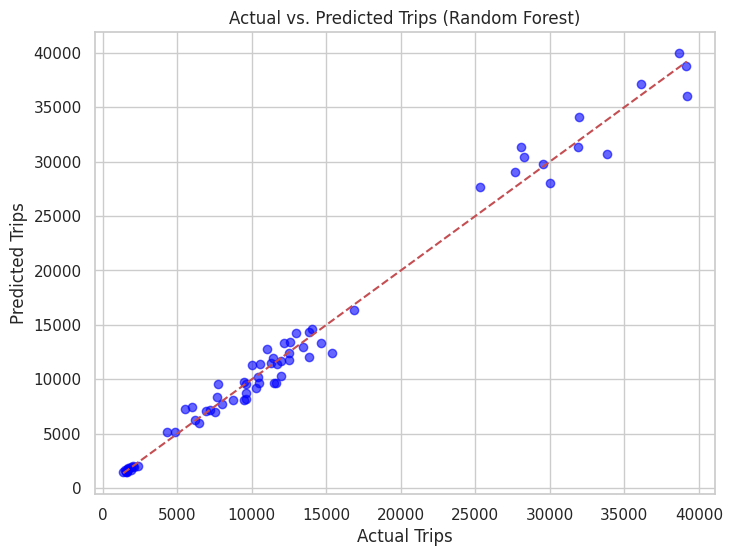

In [ ]:
# Calculate MSE and R² Score
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"\nModel Performance:")
print(f"- Mean Squared Error (MSE): {mse:.2f}")
print(f"- R² Score: {r2:.2f}")

# Actual vs Predicted Plot
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.6, color='blue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')  # Ideal line
plt.xlabel("Actual Trips")
plt.ylabel("Predicted Trips")
plt.title("Actual vs. Predicted Trips (Random Forest)")
plt.show()

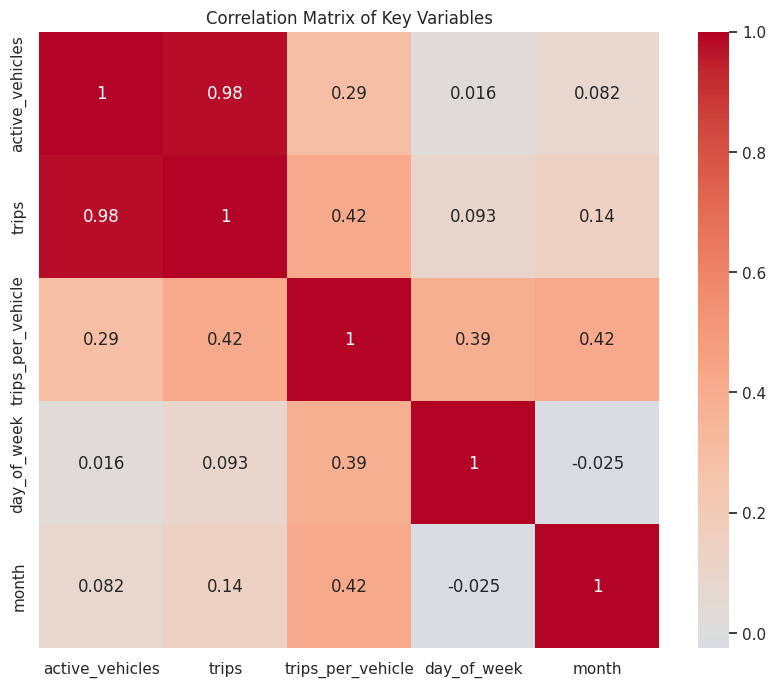

In [ ]:
# 1. Calculate trips per vehicle
df['trips_per_vehicle'] = df['trips'] / df['active_vehicles']

# 2. Correlation matrix
plt.figure(figsize=(10, 8))
corr_matrix = df[['active_vehicles', 'trips', 'trips_per_vehicle', 'day_of_week', 'month']].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0)
plt.title('Correlation Matrix of Key Variables')
plt.show()

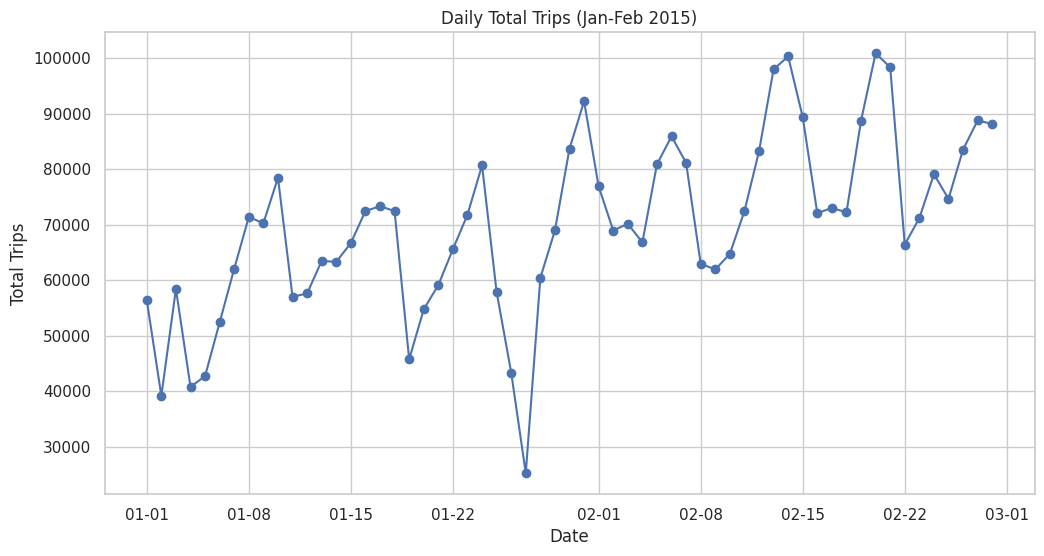

In [ ]:
# Time series of total daily trips
daily_trips = df.groupby('date')['trips'].sum().reset_index()

plt.figure(figsize=(12, 6))
plt.plot(daily_trips['date'], daily_trips['trips'], marker='o')
plt.title('Daily Total Trips (Jan-Feb 2015)')
plt.xlabel('Date')
plt.ylabel('Total Trips')
plt.gca().xaxis.set_major_formatter(DateFormatter('%m-%d'))
plt.grid(True)
plt.show()

In [ ]:
# Time series of total daily trips
daily_trips = df.groupby(df.index)['trips'].sum().reset_index()
# Rename the index column to 'date' after resetting index
daily_trips = daily_trips.rename(columns={'index': 'date'})
daily_trips['date'] = pd.to_datetime(daily_trips['date'])


# Time series decomposition
# The index of daily_trips is already date after reset_index() and rename
date_range = pd.date_range(start=daily_trips['date'].min(), end=daily_trips['date'].max())
complete_daily = daily_trips.set_index('date').reindex(date_range).fillna(method='ffill')



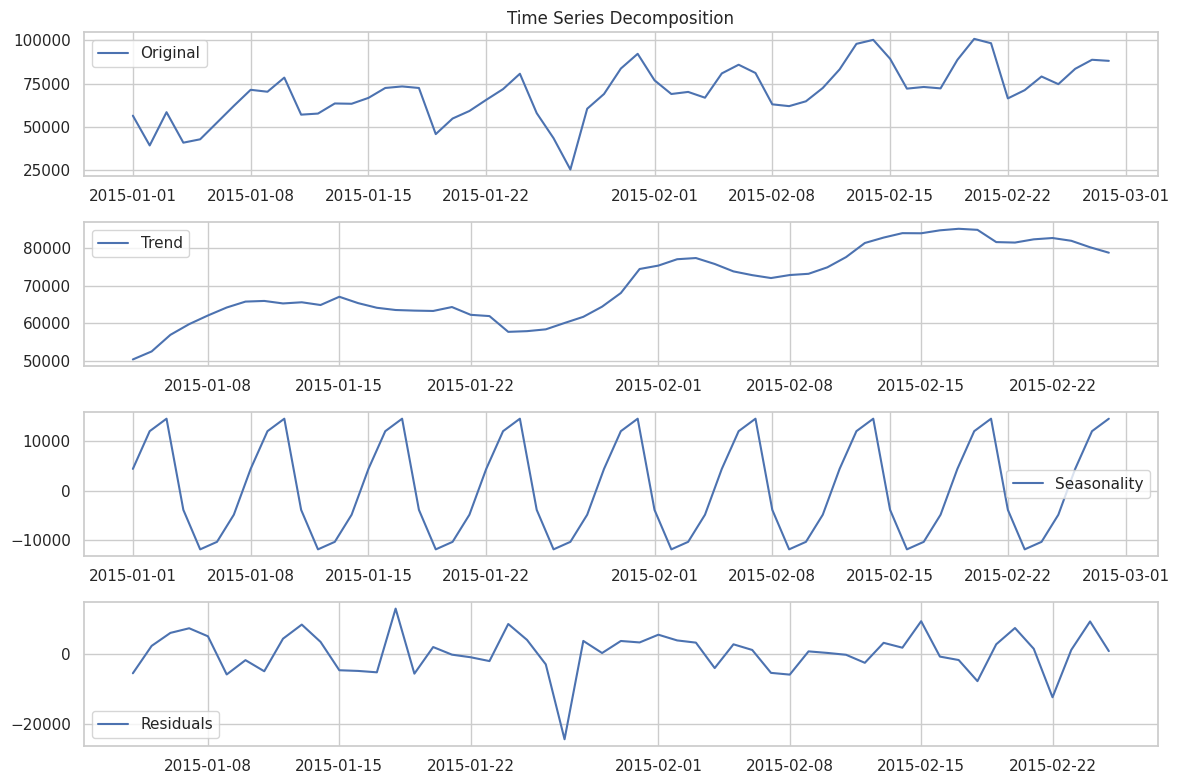

In [ ]:
# Decompose with 7-day seasonality (weekly pattern)
decomposition = seasonal_decompose(complete_daily['trips'], model='additive', period=7)

plt.figure(figsize=(12, 8))
plt.subplot(411)
plt.plot(complete_daily.index, complete_daily['trips'], label='Original')
plt.legend()
plt.title('Time Series Decomposition')

plt.subplot(412)
plt.plot(complete_daily.index, decomposition.trend, label='Trend')
plt.legend()

plt.subplot(413)
plt.plot(complete_daily.index, decomposition.seasonal, label='Seasonality')
plt.legend()

plt.subplot(414)
plt.plot(complete_daily.index, decomposition.resid, label='Residuals')
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
# Prepare daily trips data (from previous steps)
daily_trips = df.groupby('date')['trips'].sum().reset_index()
daily_trips = daily_trips.set_index('date').asfreq('D').fillna(method='ffill').reset_index()

# Split into train/test (last 7 days for testing)
train = daily_trips[:-7]
test = daily_trips[-7:]


ARIMA Forecasting:
ARIMA RMSE: 11616.64


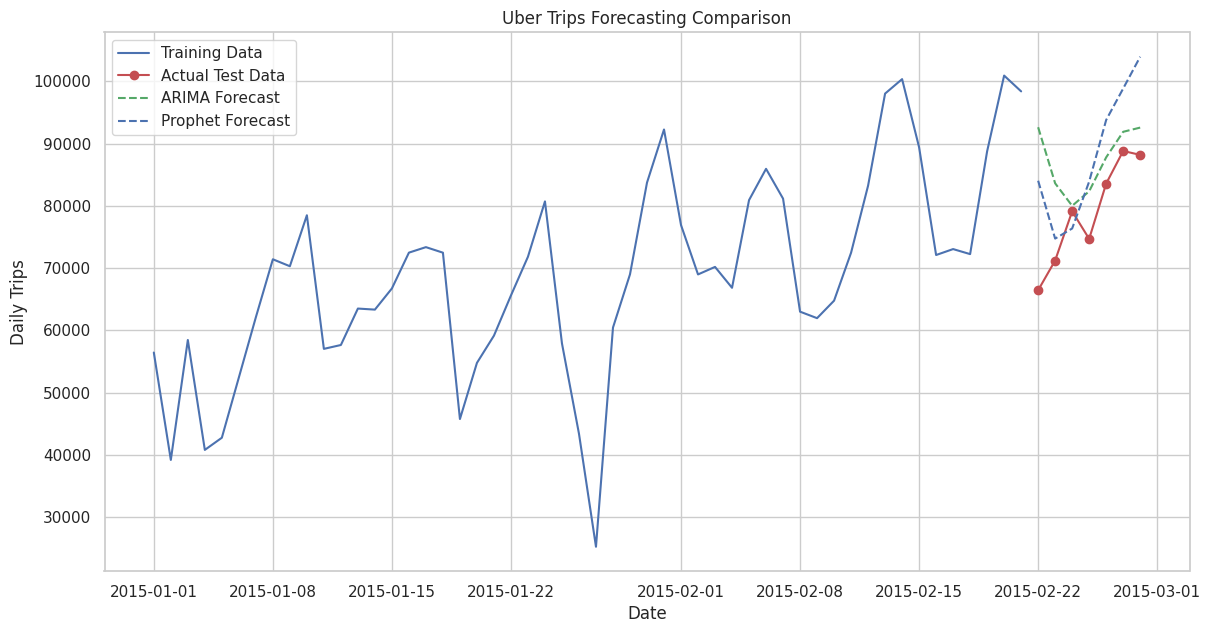

In [ ]:
# 1. ARIMA Implementation
print("\nARIMA Forecasting:")

# Fit ARIMA model (parameters can be tuned)
model_arima = ARIMA(train['trips'], order=(5,1,0))  # (p,d,q)
model_arima_fit = model_arima.fit()

# Forecast
arima_forecast = model_arima_fit.forecast(steps=7)
test['arima_forecast'] = arima_forecast.values

# Calculate RMSE
arima_rmse = np.sqrt(mean_squared_error(test['trips'], test['arima_forecast']))
print(f"ARIMA RMSE: {arima_rmse:.2f}")




# Visualization
plt.figure(figsize=(14, 7))
plt.plot(train['date'], train['trips'], label='Training Data')
plt.plot(test['date'], test['trips'], 'ro-', label='Actual Test Data')
plt.plot(test['date'], test['arima_forecast'], 'g--', label='ARIMA Forecast')
plt.plot(test['date'], test['prophet_forecast'], 'b--', label='Prophet Forecast')
plt.title('Uber Trips Forecasting Comparison')
plt.xlabel('Date')
plt.ylabel('Daily Trips')
plt.legend()
plt.grid(True)
plt.show()


DEBUG:cmdstanpy:input tempfile: /tmp/tmp8uqvk486/zlpymyhe.json
DEBUG:cmdstanpy:input tempfile: /tmp/tmp8uqvk486/b8lr9xzp.json
DEBUG:cmdstanpy:idx 0
DEBUG:cmdstanpy:running CmdStan, num_threads: None
DEBUG:cmdstanpy:CmdStan args: ['/usr/local/lib/python3.11/dist-packages/prophet/stan_model/prophet_model.bin', 'random', 'seed=45485', 'data', 'file=/tmp/tmp8uqvk486/zlpymyhe.json', 'init=/tmp/tmp8uqvk486/b8lr9xzp.json', 'output', 'file=/tmp/tmp8uqvk486/prophet_model46c9lsxu/prophet_model-20250606160606.csv', 'method=optimize', 'algorithm=newton', 'iter=10000']
16:06:06 - cmdstanpy - INFO - Chain [1] start processing
INFO:cmdstanpy:Chain [1] start processing
16:06:06 - cmdstanpy - INFO - Chain [1] done processing
INFO:cmdstanpy:Chain [1] done processing


Prophet RMSE: 11131.81


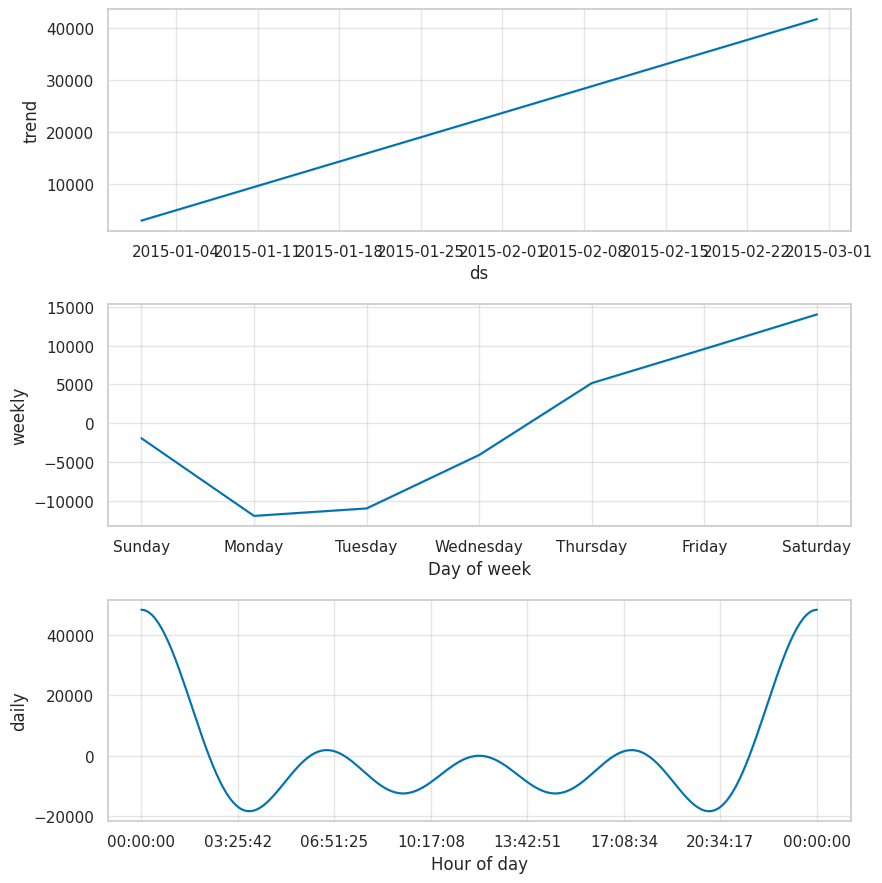

<Figure size 1400x700 with 0 Axes>

In [ ]:
# Prophet Implementation

# Prepare data for Prophet
prophet_data = train.rename(columns={'date': 'ds', 'trips': 'y'})

# Fit model
model_prophet = Prophet(
    daily_seasonality=True,
    weekly_seasonality=True,
    yearly_seasonality=False
)
model_prophet.fit(prophet_data)

# Create future dataframe
future = model_prophet.make_future_dataframe(periods=7)
forecast = model_prophet.predict(future)

# Extract predictions
test['prophet_forecast'] = forecast['yhat'].tail(7).values

# Calculate RMSE
prophet_rmse = np.sqrt(mean_squared_error(test['trips'], test['prophet_forecast']))
print(f"Prophet RMSE: {prophet_rmse:.2f}")

# Components Analysis (Prophet)
fig1 = model_prophet.plot_components(forecast)
plt.figure(figsize=(14, 7))
plt.suptitle('Prophet Components Decomposition')
plt.tight_layout()
plt.show()